## Step 1: Import Libraries

In [1]:
import keras
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
import sys
print(sys.version)

3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


In [3]:
!pip show tensorflow

Name: tensorflow
Version: 2.21.0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: c:\users\user\appdata\local\programs\python\python310\lib\site-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, setuptools, six, termcolor, typing_extensions, wrapt
Required-by: 


In [4]:
!pip show keras

Name: keras
Version: 3.12.4
Summary: Multi-backend Keras
Home-page: 
Author: 
Author-email: Keras team <keras-users@googlegroups.com>
License: Apache License 2.0
Location: c:\users\user\appdata\local\programs\python\python310\lib\site-packages
Requires: absl-py, h5py, ml-dtypes, namex, numpy, optree, packaging, rich
Required-by: tensorflow


In [5]:
import tensorflow as tf
print(tf.__version__)

2.21.0


## Step 2: Import Dataset

In [6]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

## Step 3: Data Understanding

In [7]:
x_train.shape,y_train.shape

((60000, 28, 28), (60000,))

In [8]:
x_test.shape,y_test.shape

((10000, 28, 28), (10000,))

In [9]:
x_train[1000]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  36, 146, 254, 255, 251,  95,   6,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [10]:
pd.set_option('display.max_columns', 30)
pd.DataFrame(x_train[1000])

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,36,146,254,255,251,95,6,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,0,0,3,97,234,254,254,232,254,254,35,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,0,89,140,254,254,174,67,33,200,254,190,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,108,253,254,235,51,1,0,0,12,254,253,56,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,12,216,254,244,55,0,0,0,0,6,213,254,57,0,0,0,0,0,0


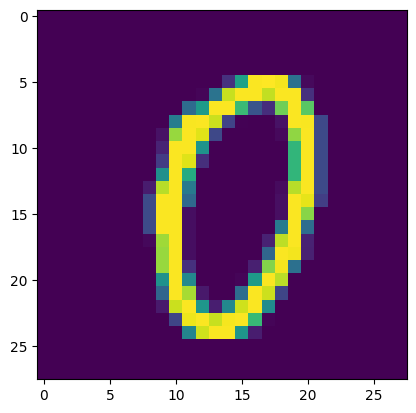

In [11]:
plt.imshow(x_train[1000])

## Step 4: Model Building

In [12]:
x_train.min(),x_train.max()

(np.uint8(0), np.uint8(255))

In [13]:
x_train=x_train/255.0        #to normalise the values so that it'll be easy to pass between layers during forward and backward pass

In [14]:
x_train.min(),x_train.max()

(np.float64(0.0), np.float64(1.0))

In [15]:
x_test.min(),x_test.max()

(np.uint8(0), np.uint8(255))

In [16]:
x_test=x_test/255.0        #to normalise the values so that it'll be easy to pass between layers during forward and backward pass

In [17]:
x_train.min(),x_train.max()

(np.float64(0.0), np.float64(1.0))

## Step 5: Model Building

In [18]:
from keras.models import Sequential
from keras.layers import Flatten,Dense
model = Sequential()
model.add(Flatten())
model.add(Dense( units=100,activation="relu"))
model.add(Dense(units=10,activation="softmax"))

## Step 6: Model Compiling

In [22]:
model.compile(optimizer='rmsprop',loss="sparse_categorical_crossentropy",metrics=["sparse_categorical_accuracy"])

In [23]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## Step 7: Model Training || Step 8: Model Testing || Step 9: Model Evaluation

In [24]:
model.fit(x=x_train,y=y_train,batch_size=32,epochs=10,validation_data=(x_test,y_test))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.2644 - sparse_categorical_accuracy: 0.9252 - val_loss: 0.1368 - val_sparse_categorical_accuracy: 0.9590
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.1244 - sparse_categorical_accuracy: 0.9633 - val_loss: 0.1053 - val_sparse_categorical_accuracy: 0.9685
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0911 - sparse_categorical_accuracy: 0.9733 - val_loss: 0.0891 - val_sparse_categorical_accuracy: 0.9743
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0721 - sparse_categorical_accuracy: 0.9792 - val_loss: 0.0868 - val_sparse_categorical_accuracy: 0.9755
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0612 - sparse_categorical_accuracy: 0.9819 - val_loss: 0.0854 - val_sparse_categorical_accuracy: 0.9750
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0518 - sparse_categorical_accuracy: 0.9845 - val_loss: 0.0868 - val_sparse_categorical_accuracy:

## Step 10: Manual Model Testing

In [27]:
y_pred=model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (32, 784)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (32, 100)                   │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (32, 10)                    │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 159,022 (621.18 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 79,512 (310.60 KB)

In [28]:
x_test[400]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [29]:
y_test[400]

np.uint8(2)

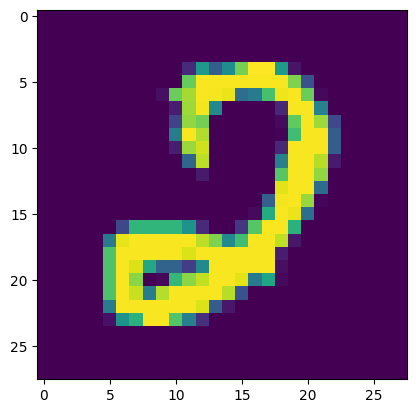

In [30]:
plt.imshow(x_test[400])

In [33]:
import numpy as np
np.argmax(y_pred[400])

np.int64(2)

## Let's Build the model for prediction

## Step 1: Take out the intelligence file 

In [34]:
model.save("digits_intel.h5")

## Step 2: Image upload and resizing

In [35]:
from PIL import Image
image_path="test_image.png"

In [37]:
image=Image.open(image_path)
image=image.convert("L")
image=image.resize(size=(28,28))
image=np.array(image)

## Step 3: Do the prediction

In [41]:
from keras.models import load_model
prediction_model=load_model("digits_intel.h5")

In [49]:
def predict_image(image):
    image=image/255.0
    image=np.expand_dims(a=image,axis=0)
    prediction=prediction_model.predict(image)
    return np.argmax(prediction)

In [50]:
predict_image(image)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step


np.int64(5)